<a href="https://colab.research.google.com/github/kokilahemachandra-afk/srilanka-ntl-midterm/blob/main/notebooks/04_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Can we trust night-time lights? Checks against official data

All results in notebook 03 assume that night-time light measures economic activity.
This notebook tests that assumption against official data in three ways:

1. **Districts, levels (HIES 2019):** do brighter districts have higher household
   income and spending, and less poverty? (25 districts)
2. **Provinces, levels (CBSL provincial GDP 2024):** do brighter provinces have more
   GDP per km²? (9 provinces)
3. **Provinces, changes (CBSL provincial GDP 2019–2023):** when a province's share
   of light rises, does its share of GDP rise too?

Checks 1 and 2 test whether light shows **where** activity is.
Check 3 tests whether light follows **how activity changes**, which matters for
the convergence results.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})

REPO = "https://raw.githubusercontent.com/kokilahemachandra-afk/srilanka-ntl-midterm/main/"
annual = pd.read_csv(REPO + "data/processed/lka_ds339_ntl_annual.csv")
print(annual.shape)      # expect (4068, 11)

(4068, 11)


## Step V1 · Enter the official data

The official figures are only published in PDF reports, so we type them in once
here and save them as CSV files (upload them to `data/raw/` on GitHub).

- **HIES 2019, by district:** Department of Census and Statistics, *Household Income
  and Expenditure Survey 2019*. Mean monthly income of income receivers (Fig. 2.5),
  mean monthly household expenditure (Fig. 3.1), multidimensional poverty headcount
  (Table 6.4). Income and expenditure were read from the report's charts and are
  approximate (± about 1%); the poverty figures are exact. *To do for the final
  version: replace income with the exact values in Table 2.8.*
- **Provincial GDP:** Central Bank of Sri Lanka. Shares 2019–2023 from *Sri Lanka
  Socio-Economic Data 2025*, p. 47; 2024 values (Rs. million, current prices) from
  the PGDP 2024 press release, 22 December 2025.

In [ ]:
hies2019 = pd.DataFrame({
    "district": ["Colombo","Gampaha","Kalutara","Kandy","Matale","Nuwara Eliya","Galle","Matara",
                 "Hambantota","Jaffna","Mannar","Vavuniya","Mullaitivu","Kilinochchi","Batticaloa",
                 "Ampara","Trincomalee","Kurunegala","Puttalam","Anuradhapura","Polonnaruwa",
                 "Badulla","Monaragala","Ratnapura","Kegalle"],
    "mean_income": [66846,53897,43789,42417,32847,28924,39958,35556,38614,30531,28641,36501,33126,
                    27413,28640,37691,31125,39365,49582,38814,36912,38021,32992,29476,32534],
    "hh_expenditure": [108707,84224,65862,66810,49397,41810,58362,59569,54052,42069,49741,55948,34052,
                       37155,41293,52759,44741,57586,63621,52672,51121,46810,44828,44741,50172],
    "mpi_headcount": [3.5,5.1,11.5,21.9,20.4,44.2,10.0,17.4,20.4,10.0,27.0,26.3,13.8,15.2,20.2,13.9,
                      14.6,11.8,10.0,18.0,20.2,36.6,32.7,28.0,18.2]})

pgdp_share = pd.DataFrame({
    "province": ["Western","Central","Southern","Northern","Eastern","North Western","North Central","Uva","Sabaragamuwa"],
    "2019": [42.1,10.4,9.4,4.7,5.2,10.9,4.7,5.5,6.9],
    "2020": [42.1,10.6,9.1,4.2,5.9,10.9,5.1,5.0,7.0],
    "2021": [42.6,10.3,9.1,4.2,5.5,11.3,5.0,4.9,7.1],
    "2022": [43.9,10.0,9.0,4.0,5.1,11.1,4.8,4.8,7.2],
    "2023": [43.9,10.3,9.3,4.5,4.7,10.9,4.8,4.7,7.0]})

pgdp_2024 = pd.DataFrame({
    "province": ["Central","Eastern","North Central","North Western","Northern","Sabaragamuwa","Southern","Uva","Western"],
    "gdp_2024_rs_mn": [3202384,1496226,1367650,3447546,1321752,2288330,2672395,1439464,12662817]})

hies2019.to_csv("hies2019_district.csv", index=False)
pgdp_share.to_csv("cbsl_pgdp_shares_2019_2023.csv", index=False)
pgdp_2024.to_csv("cbsl_pgdp_2024.csv", index=False)
print("Saved 3 files")

Saved 3 files


### Figure 2 for the slides · Light vs household spending (cleaner labels)
This uses the same data and the same correlation as above, but labels only the 8 districts discussed in the talk so the names don't overlap on a slide.

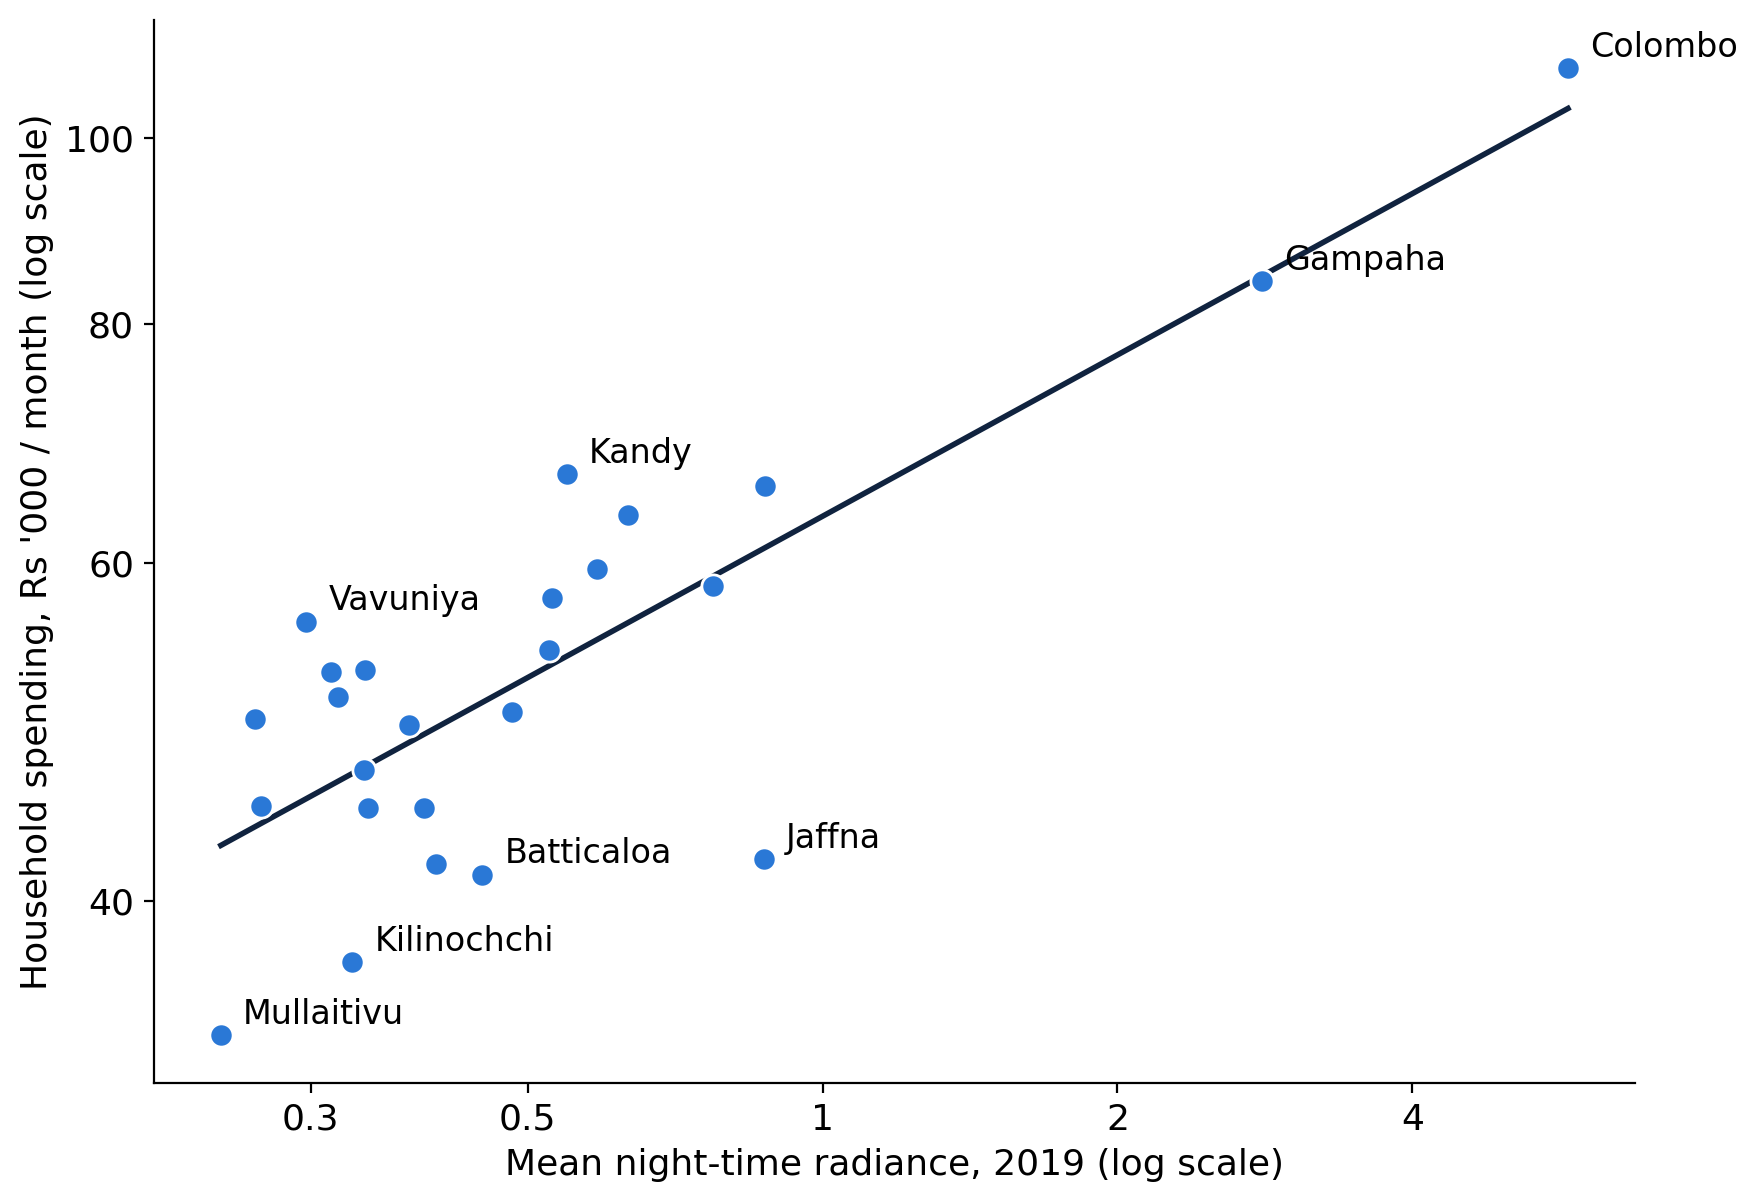

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter
import pandas as pd
d = pd.read_csv("https://raw.githubusercontent.com/kokilahemachandra-afk/srilanka-ntl-midterm/main/data/processed/check_hies2019_district.csv")
fig, ax = plt.subplots(figsize=(9, 6.2), dpi=200)
ax.scatter(d.light_density, d.hh_expenditure/1000, s=70, color="#2A78D6", edgecolor="white", zorder=3)
b = np.polyfit(np.log(d.light_density), np.log(d.hh_expenditure), 1)
xs = np.linspace(np.log(d.light_density).min(), np.log(d.light_density).max(), 50)
ax.plot(np.exp(xs), np.exp(b[1] + b[0]*xs)/1000, color="#10233F", lw=2)
ax.set_xscale("log"); ax.set_yscale("log")
for n in ["Colombo","Gampaha","Jaffna","Mullaitivu","Kilinochchi","Kandy","Vavuniya","Batticaloa"]:
    r = d[d.district == n].iloc[0]
    ax.annotate(n, (r.light_density, r.hh_expenditure/1000), xytext=(8, 4), textcoords="offset points", fontsize=12)
ax.yaxis.set_major_locator(FixedLocator([40, 60, 80, 100])); ax.yaxis.set_minor_locator(FixedLocator([]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}"))
ax.xaxis.set_major_locator(FixedLocator([0.3, 0.5, 1, 2, 4])); ax.xaxis.set_minor_locator(FixedLocator([]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
ax.set_xlabel("Mean night-time radiance, 2019 (log scale)")
ax.set_ylabel("Household spending, Rs '000 / month (log scale)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_validation_slide.png", dpi=200); plt.show()

## Step V2 · Check 1: districts (HIES 2019)

**Why:** this is the most detailed official test we have: 25 districts, measured
directly from households by survey, not modelled.

**How:** for each district we compute light density in 2019 (mean radiance weighted
by DS-division area, i.e. light per km²) and correlate its log with:
- log household expenditure and log income (expect **positive**)
- multidimensional poverty headcount (expect **negative**)

We repeat it without Colombo, to check that one very bright district is not driving
the result.

In [ ]:
y19 = annual[annual["year"] == 2019].copy()
y19["light_x_area"] = y19["ntl_mean"] * y19["area_sqkm"]
dist = y19.groupby("district").agg(light_x_area=("light_x_area", "sum"), area_km2=("area_sqkm", "sum"))
dist["light_density"] = dist["light_x_area"] / dist["area_km2"]
dist = dist.join(hies2019.set_index("district"))
print("Missing after join:", dist.isna().sum().sum())          # expect 0

rows = []
for col, log_it in [("hh_expenditure", True), ("mean_income", True), ("mpi_headcount", False)]:
    yv = np.log(dist[col]) if log_it else dist[col]
    r, p = stats.pearsonr(np.log(dist["light_density"]), yv)
    d2 = dist.drop("Colombo")
    y2 = np.log(d2[col]) if log_it else d2[col]
    r2, _ = stats.pearsonr(np.log(d2["light_density"]), y2)
    rows.append({"HIES 2019 measure": col, "r": round(r, 2), "p_value": round(p, 4),
                 "r_without_Colombo": round(r2, 2)})
check_hies = pd.DataFrame(rows)
dist.round(3).to_csv("check_hies2019_district.csv")
check_hies

Missing after join: 0


,HIES 2019 measure,r,p_value,r_without_Colombo
0,hh_expenditure,0.81,0.0000,0.68
1,mean_income,0.77,0.0000,0.61
2,mpi_headcount,-0.60,0.0015,-0.55


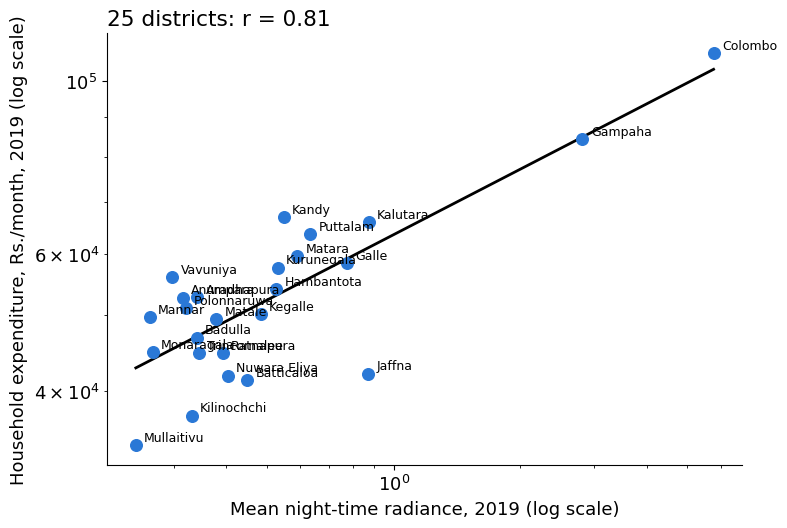

In [ ]:
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.scatter(dist["light_density"], dist["hh_expenditure"], s=70, color="#2a78d6", zorder=3)
for name, row in dist.iterrows():
    ax.annotate(name, (row["light_density"], row["hh_expenditure"]),
                textcoords="offset points", xytext=(6, 3), fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
b, c = np.polyfit(np.log(dist["light_density"]), np.log(dist["hh_expenditure"]), 1)
xs = np.linspace(dist["light_density"].min(), dist["light_density"].max(), 50)
ax.plot(xs, np.exp(c) * xs ** b, color="black", lw=2)
ax.set_xlabel("Mean night-time radiance, 2019 (log scale)")
ax.set_ylabel("Household expenditure, Rs./month, 2019 (log scale)")
ax.set_title(f"25 districts: r = {check_hies.loc[0, 'r']}", loc="left")
plt.savefig("fig_check_hies2019.png", dpi=200, bbox_inches="tight")
plt.show()

**Result:** brighter districts spend more (r = 0.81), earn more (r = 0.77) and have
less multidimensional poverty (r = −0.60), all with p < 0.01. Without Colombo the
correlations are smaller but hold (0.68, 0.61, −0.55). Notable exceptions: Jaffna
is bright for its income (a dense town), and Nuwara Eliya is dim with the highest
poverty (44%).

## Step V3 · Check 2: provinces, levels (CBSL GDP 2024)

**Why:** GDP is the standard measure of economic activity, but in Sri Lanka it is
only published down to provinces.

**How:** compare light per km² with GDP per km². We also compare **totals** (total
light vs total GDP) to show why the analysis uses mean radiance: totals over-weight
large rural provinces.

Note: provincial GDP is itself estimated top-down by the Central Bank (national GDP
split using provincial indicators), so this is a check against an estimate.

In [ ]:
y24 = annual[annual["year"] == 2024].copy()
y24["light_x_area"] = y24["ntl_mean"] * y24["area_sqkm"]
prov = y24.groupby("province").agg(light_x_area=("light_x_area", "sum"),
                                   total_light=("ntl_sum", "sum"), area_km2=("area_sqkm", "sum"))
prov["light_density"] = prov["light_x_area"] / prov["area_km2"]
prov = prov.join(pgdp_2024.set_index("province"))
prov["gdp_density"] = prov["gdp_2024_rs_mn"] / prov["area_km2"]

r_density, p_density = stats.pearsonr(np.log(prov["light_density"]), np.log(prov["gdp_density"]))
r_total, _ = stats.pearsonr(np.log(prov["total_light"]), np.log(prov["gdp_2024_rs_mn"]))
print("Density: r =", round(r_density, 2), "| p =", round(p_density, 4))   # expect 0.92, 0.0005
print("Totals:  r =", round(r_total, 2))                                    # expect 0.61
prov.round(3).to_csv("check_pgdp_2024.csv")

Density: r = 0.92 | p = 0.0005
Totals:  r = 0.61


## Step V4 · Check 3: provinces, changes (CBSL GDP shares 2019→2023)

**Why:** checks 1 and 2 compare **levels** in a single year. But convergence is about
**change**: dim places growing faster. So we test whether a province's share of
national light moves in the same direction as its share of national GDP.

**How:** for 2019 and 2023, compute each province's share of total light (%), then
compare the change in light share with the change in GDP share. Shares remove
inflation and national growth, which affect all provinces equally.

In [ ]:
tl = annual.groupby(["province", "year"])["ntl_sum"].sum().unstack()
light_share = tl.div(tl.sum(), axis=1) * 100

chg = pgdp_share.set_index("province")[["2019", "2023"]].astype(float)
chg.columns = ["gdp_share_2019", "gdp_share_2023"]
chg["light_share_2019"] = light_share[2019]
chg["light_share_2023"] = light_share[2023]
chg["change_gdp_share"] = chg["gdp_share_2023"] - chg["gdp_share_2019"]
chg["change_light_share"] = chg["light_share_2023"] - chg["light_share_2019"]

r_all, p_all = stats.pearsonr(chg["change_light_share"], chg["change_gdp_share"])
no_w = chg.drop("Western")
r_now, p_now = stats.pearsonr(no_w["change_light_share"], no_w["change_gdp_share"])
print("All 9 provinces:  r =", round(r_all, 2), "| p =", round(p_all, 4))     # expect −0.92, 0.0004
print("Without Western:  r =", round(r_now, 2), "| p =", round(p_now, 2))     # expect −0.48, 0.22
chg.round(3).to_csv("check_change_2019_2023.csv")
chg[["change_gdp_share", "change_light_share"]].round(2)

All 9 provinces:  r = -0.92 | p = 0.0004
Without Western:  r = -0.48 | p = 0.23


,change_gdp_share,change_light_share
province,,
Western,1.8,-5.49
Central,-0.1,0.33
Southern,-0.1,-0.12
Northern,-0.2,1.57
Eastern,-0.5,1.32
North Western,0.0,-0.72
North Central,0.1,1.42
Uva,-0.8,1.39
Sabaragamuwa,0.1,0.30


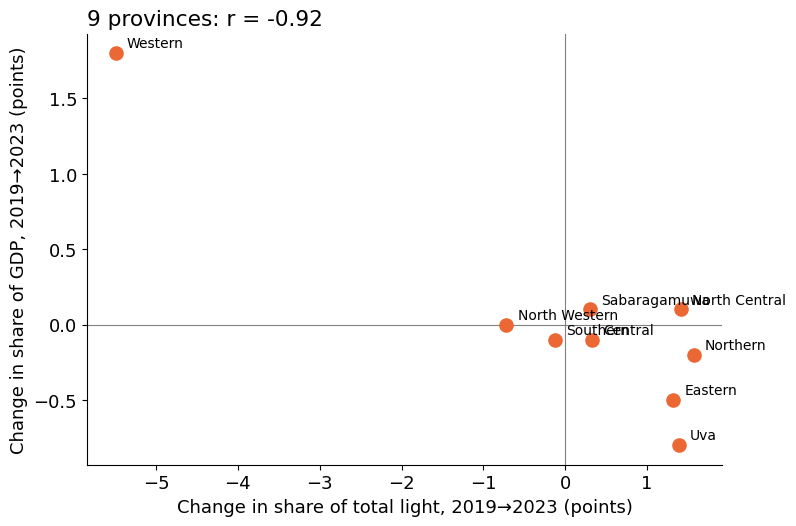

In [ ]:
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.scatter(chg["change_light_share"], chg["change_gdp_share"], s=90, color="#eb6834", zorder=3)
for name, row in chg.iterrows():
    ax.annotate(name, (row["change_light_share"], row["change_gdp_share"]),
                textcoords="offset points", xytext=(8, 4), fontsize=10)
ax.set_xlabel("Change in share of total light, 2019→2023 (points)")
ax.set_ylabel("Change in share of GDP, 2019→2023 (points)")
ax.set_title(f"9 provinces: r = {r_all:.2f}", loc="left")
plt.savefig("fig_check_change.png", dpi=200, bbox_inches="tight")
plt.show()

**Result:** the changes do **not** match. Western Province's share of GDP rose by
1.8 points while its share of light fell by 5.5 points; this one province drives the
strong negative correlation (r = −0.92). Among the other eight provinces there is
no clear relationship (r = −0.48, p = 0.22).

Possible reasons (not yet tested): rural electrification and new street lighting
brightening dim areas faster than their economies grow; LED street lights in cities,
which the VIIRS sensor sees less well; provincial GDP being a top-down estimate in
current prices; and the 2022 economic crisis inside this short window.

In [ ]:
from google.colab import files
for f in ["hies2019_district.csv", "cbsl_pgdp_shares_2019_2023.csv", "cbsl_pgdp_2024.csv",
          "check_hies2019_district.csv", "check_pgdp_2024.csv", "check_change_2019_2023.csv",
          "fig_check_hies2019.png", "fig_check_change.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step V5 · Check 4: districts, changes (HIES 2016 → 2019)

**Why:** check 3 found that changes in light did not follow changes in GDP share,
but it had only 9 provinces and used modelled GDP. HIES measures spending directly
from households in all 25 districts, in two survey rounds (2016 and 2019), so we can
test change at a finer level.

**Why expenditure, not income:** household expenditure is defined the same way in
both reports. (The 2019 file gives income per *income receiver*, while 2016 gives
income per *household*, so they cannot be compared.) Spending is also a common
measure of living standards.

**Data:** HIES 2016 Final Report (Department of Census and Statistics): mean monthly
household expenditure by district with its coefficient of variation (Table 1.3, exact)
and mean monthly household income (Table 2.1, exact). HIES 2019 expenditure as in Step V1.

**How:** growth = log(2019 / 2016) × 100, for spending and for light per km².
Inflation affects all districts equally, so it does not change the correlation.

**Enter HIES 2016**

In [ ]:
hies2016 = pd.DataFrame({
    "district": ["Colombo","Gampaha","Kalutara","Kandy","Matale","Nuwara Eliya","Galle","Matara",
                 "Hambantota","Jaffna","Mannar","Vavuniya","Mullaitivu","Kilinochchi","Batticaloa",
                 "Ampara","Trincomalee","Kurunegala","Puttalam","Anuradhapura","Polonnaruwa",
                 "Badulla","Monaragala","Ratnapura","Kegalle"],
    "hh_expenditure": [90670,64563,64268,54400,47744,44059,53350,47322,56890,43571,46795,51754,32576,
                       28483,32807,42646,39247,55718,55076,48299,47910,41234,35487,38589,48511],
    "expenditure_cv": [4.6,3.5,4.7,4.3,4.3,4.7,3.9,3.5,4.9,5.7,5.9,4.9,9.5,6.9,4.3,3.7,6.8,4.4,5.5,
                       4.6,4.7,5.5,4.3,4.0,4.1],
    "hh_income_mean": [104581,72834,69171,55194,56075,46517,63093,54019,59932,47731,45608,58625,31868,
                       31576,40356,43821,46138,59661,61981,58326,64525,53236,48842,46977,51865]})
hies2016.to_csv("hies2016_district.csv", index=False)
print("Saved hies2016_district.csv")

Saved hies2016_district.csv


**Compare growth**

In [ ]:
annual["light_x_area"] = annual["ntl_mean"] * annual["area_sqkm"]
dl = annual.groupby(["district", "year"]).agg(light_x_area=("light_x_area", "sum"),
                                              area_km2=("area_sqkm", "sum"))
dl["light_density"] = dl["light_x_area"] / dl["area_km2"]
light = dl["light_density"].unstack()                    # districts × years

chg_d = pd.DataFrame({
    "spend_2016": hies2016.set_index("district")["hh_expenditure"],
    "spend_2019": hies2019.set_index("district")["hh_expenditure"],
    "light_2016": light[2016], "light_2019": light[2019]})
chg_d["growth_spend_%"] = np.log(chg_d["spend_2019"] / chg_d["spend_2016"]) * 100
chg_d["growth_light_%"] = np.log(chg_d["light_2019"] / chg_d["light_2016"]) * 100
print("Missing:", chg_d.isna().sum().sum())                                   # expect 0

r, p = stats.pearsonr(chg_d["growth_light_%"], chg_d["growth_spend_%"])
rho, p_rho = stats.spearmanr(chg_d["growth_light_%"], chg_d["growth_spend_%"])
print(f"Growth 2016→2019: r = {r:.2f} (p = {p:.2f}) | Spearman = {rho:.2f} (p = {p_rho:.2f})")   # −0.29 (0.16)

r16, _ = stats.pearsonr(np.log(chg_d["light_2016"]), np.log(chg_d["spend_2016"]))
print(f"Levels 2016, for comparison: r = {r16:.2f}")                                            # 0.74

# Did the gaps narrow? Spread (std. dev.) of logs across the 25 districts
print("Spread of log spending: 2016 =", round(np.log(chg_d["spend_2016"]).std(), 3),
      "| 2019 =", round(np.log(chg_d["spend_2019"]).std(), 3))                                  # 0.248 → 0.250
print("Spread of log light:    2016 =", round(np.log(chg_d["light_2016"]).std(), 3),
      "| 2019 =", round(np.log(chg_d["light_2019"]).std(), 3))                                  # 0.855 → 0.727

# How noisy is the survey? Approx. s.e. of growth, assuming a similar CV in 2019
se_growth = np.sqrt(2) * hies2016.set_index("district")["expenditure_cv"]
print("Typical survey error in spending growth: ±", round(se_growth.median(), 1), "points",
      "| spread of observed growth:", round(chg_d["growth_spend_%"].std(), 1), "points")       # 6.5 vs 9.8

chg_d.round(2).to_csv("check_change_hies_2016_2019.csv")

Missing: 0
Growth 2016→2019: r = -0.29 (p = 0.16) | Spearman = -0.18 (p = 0.39)
Levels 2016, for comparison: r = 0.74
Spread of log spending: 2016 = 0.248 | 2019 = 0.25
Spread of log light:    2016 = 0.855 | 2019 = 0.727
Typical survey error in spending growth: ± 6.5 points | spread of observed growth: 9.8 points


**Chart**

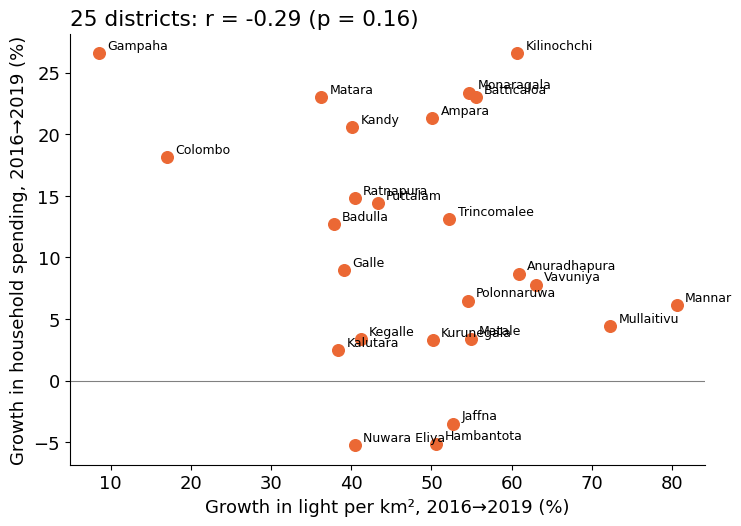

In [ ]:
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.scatter(chg_d["growth_light_%"], chg_d["growth_spend_%"], s=70, color="#eb6834", zorder=3)
for name, row in chg_d.iterrows():
    ax.annotate(name, (row["growth_light_%"], row["growth_spend_%"]),
                textcoords="offset points", xytext=(6, 3), fontsize=9)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Growth in light per km², 2016→2019 (%)")
ax.set_ylabel("Growth in household spending, 2016→2019 (%)")
ax.set_title(f"25 districts: r = {r:.2f} (p = {p:.2f})", loc="left")
plt.savefig("fig_check_change_hies.png", dpi=200, bbox_inches="tight")
plt.show()

**Result:**
- **Levels match:** in 2016, as in 2019, brighter districts spend more (r = 0.74).
- **Changes do not match:** districts whose light grew faster did *not* have faster
  spending growth (r = −0.29, p = 0.16, not significant).
- **Gaps:** across districts, the spread of light fell (0.86 → 0.73), but the spread
  of household spending did not change (0.25 → 0.25). Light converged; spending did not.

**Limitation:** this test is weak. Each district's spending growth has a survey
error of about ±6.5 points, against a spread of 9.8 points between districts, so
about half of the differences in spending growth are sampling noise. Three years is
also a short window. The test cannot prove that light and spending move apart, but
it gives **no evidence that changes in light track changes in living standards**.

This agrees with check 3 (provinces): light is a good measure of **where** activity
is, but its **changes** may reflect other things, such as electrification, new
street lighting or changes in lighting technology.

## Summary of the checks

| Check | Data | Result |
|---|---|---|
| 1. Districts, levels | HIES 2019, 25 districts | ✓ spending r = 0.81, income r = 0.77, poverty r = −0.60 |
| 2. Provinces, levels | CBSL GDP 2024, 9 provinces | ✓ r = 0.92 (density); totals only r = 0.61 |
| 3. Provinces, changes | CBSL GDP shares 2019→2023 | ✗ no match; Western moves the opposite way |
| 4. Districts, changes | HIES spending 2016→2019, 25 districts | ✗ no match (r = −0.29, n.s.); light converged, spending did not |

**Conclusion:** night-time light is a good guide to **where** economic activity is
(checks 1–2). But over short periods its **changes** do not follow changes in GDP
or household spending (checks 3–4). The convergence found in notebook 03 is
therefore convergence **in light**, and should not yet be read as convergence in
living standards.

In [ ]:
from google.colab import files
for f in ["hies2016_district.csv", "check_change_hies_2016_2019.csv", "fig_check_change_hies.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>